# Beyond the Chains
## 01 — NFL Data Rushing Analysis Acquisition & Initial Exploration

### Objective
Construct and explore a historical NFL dataset spanning the
2000–2025 seasons.

### Research Questions
1. What datasets and variables are available?
2. How many observations are recorded?
3. How complete are the datasets?
4. Are statistical variables consistently available across seasons?
5. What preprocessing will be necessary before analysis?

### Data Source
NFL play-by-play data accessed through `nflreadpy`.

### Methodology
We will initially examine the 2000 season before expanding
the analysis to all 26 seasons.

In [1]:
# import necessary libraires
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:


SEASONS = list(range(2000, 2026))

team_stats = nfl.load_team_stats(
    seasons=SEASONS,
    summary_level="week"
).to_pandas()

# Regular-season games only
team_stats = team_stats.loc[
    team_stats["season_type"] == "REG"
].copy()

print("Dataset shape:", team_stats.shape)
display(team_stats.head())

Dataset shape: (13418, 138)


,season,week,team,season_type,game_id,opponent_team,completions,attempts,passing_yards,passing_tds,...,pt_yards,pt_inside_20,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards
0,2000,1,ARI,REG,2000_01_ARI_NYG,NYG,28,49,318,2,...,211,1,0,0,0,2,3,18,0,193
1,2000,1,ATL,REG,2000_01_SF_ATL,SF,16,31,264,2,...,95,0,0,0,1,0,1,0,0,75
2,2000,1,BAL,REG,2000_01_BAL_PIT,PIT,18,32,199,1,...,281,4,2,1,2,2,0,0,0,241
3,2000,1,BUF,REG,2000_01_TEN_BUF,TEN,13,26,174,1,...,375,2,1,0,0,2,6,60,0,315
4,2000,1,CAR,REG,2000_01_CAR_WAS,WAS,17,26,183,1,...,214,2,0,0,0,2,3,15,0,199


In [3]:
#peaking at rushing yards
rushing = team_stats[
    ["season", "team", "week", "rushing_yards"]
].dropna()

display(rushing["rushing_yards"].describe())

count    13418.000000
mean       114.798405
std         51.850518
min        -18.000000
25%         78.000000
50%        108.000000
75%        145.000000
max        407.000000
Name: rushing_yards, dtype: float64

In [ ]:
print("Duplicate team-games:",
      team_stats.duplicated(
          subset=["season", "game_id", "team"]
      ).sum())

print("Missing rushing yards:",
      team_stats["rushing_yards"].isna().sum())

In [4]:
# distrbution stats 
x = rushing["rushing_yards"]

print(f"Mean: {x.mean():.2f}")
print(f"Median: {x.median():.2f}")
print(f"Standard deviation: {x.std():.2f}")
print(f"Variance: {x.var():.2f}")
print(f"Skewness: {x.skew():.3f}")
print(f"Excess kurtosis: {x.kurt():.3f}")
print(f"IQR: {x.quantile(.75) - x.quantile(.25):.2f}")

Mean: 114.80
Median: 108.00
Standard deviation: 51.85
Variance: 2688.48
Skewness: 0.789
Excess kurtosis: 0.935
IQR: 67.00


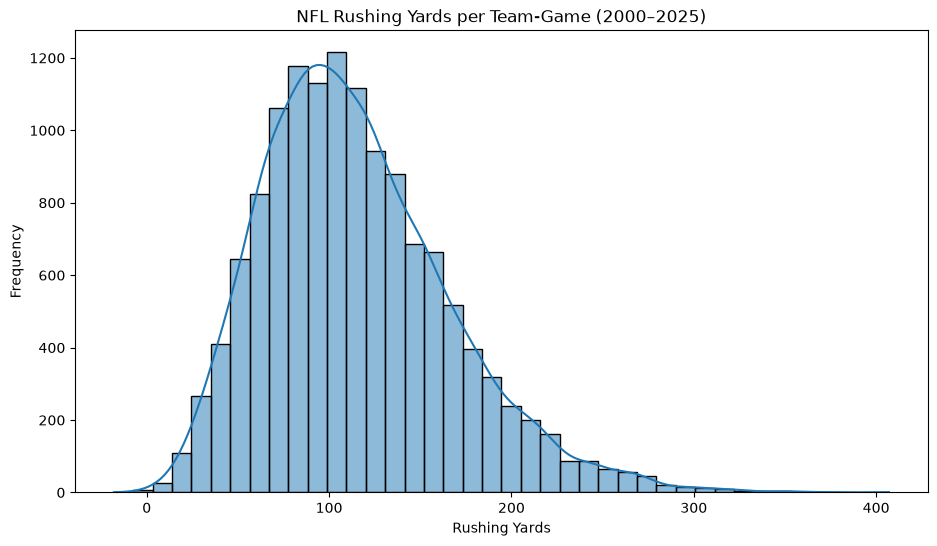

In [5]:
plt.figure(figsize=(11, 6))

sns.histplot(
    data=rushing,
    x="rushing_yards",
    bins=40,
    kde=True
)

plt.title("NFL Rushing Yards per Team-Game (2000–2025)")
plt.xlabel("Rushing Yards")
plt.ylabel("Frequency")
plt.show()


## Historical Trends in NFL Rushing Performance (2000–2025)

### Objective
Examine how the distribution of rushing yards per team-game has
changed across 26 NFL regular seasons.

### Research Questions
1. Has average rushing production changed over time?
2. Has game-to-game variability increased or decreased?
3. Have the skewness and kurtosis of rushing-yard distributions changed?

In [6]:
season_summary = (
    rushing.groupby("season")["rushing_yards"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        variance="var",
        minimum="min",
        maximum="max",
        skewness="skew",
        kurtosis=pd.Series.kurt
    )
    .reset_index()
)

season_summary["range"] = (
    season_summary["maximum"] - season_summary["minimum"]
)

display(season_summary.round(2))

,season,count,mean,median,std,variance,minimum,maximum,skewness,kurtosis,range
0,2000,492,112.76,104.0,55.21,3048.69,4,407,0.94,1.82,403
1,2001,488,113.61,103.0,51.62,2664.29,19,337,0.82,0.73,318
2,2002,504,117.97,109.5,53.77,2891.38,17,330,0.89,0.90,313
3,2003,512,117.88,111.5,51.41,2642.91,9,343,0.69,0.51,334
4,2004,512,116.71,110.0,51.69,2672.01,5,275,0.52,-0.12,270
5,2005,512,112.48,105.0,51.11,2611.82,6,320,0.54,0.34,314
6,2006,512,117.33,111.0,54.74,2996.13,-3,375,0.73,1.01,378
7,2007,512,110.95,104.5,50.87,2588.03,-18,378,0.96,2.19,396
8,2008,512,115.90,108.5,54.14,2930.97,14,332,0.94,1.30,318
9,2009,512,116.66,110.0,54.41,2959.92,4,351,0.99,1.53,347


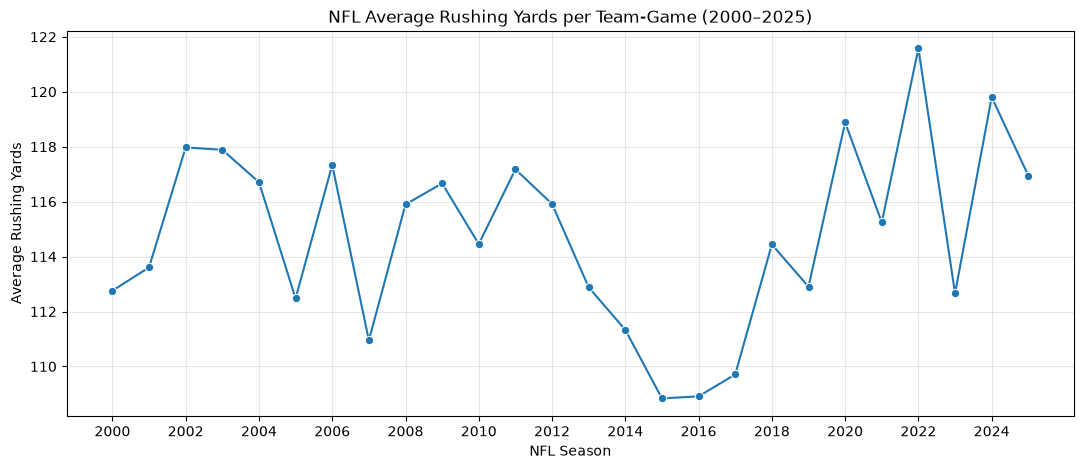

In [7]:
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=season_summary,
    x="season",
    y="mean",
    marker="o"
)

plt.title("NFL Average Rushing Yards per Team-Game (2000–2025)")
plt.xlabel("NFL Season")
plt.ylabel("Average Rushing Yards")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()

### Historical Trends in Mean Rushing Production (2000–2025)

The figure illustrates the league-wide average rushing yards per team-game across 26 NFL regular seasons, from 2000 through 2025.

Across the study period, the pooled mean rushing production was **114.80 yards per team-game**, with a median of **108.00 yards**. However, seasonal rushing averages fluctuated considerably, displaying no consistent upward or downward trend.

Between 2000 and 2012, average rushing production generally remained between approximately 113 and 118 yards per team-game, with several intermittent declines. A more noticeable downward movement occurred from 2013 through 2015, reaching the **lowest seasonal mean of 108.84 yards in 2015**.

Beginning in 2018, rushing production generally recovered, although substantial year-to-year fluctuations persisted. The **highest seasonal mean occurred in 2022 at 121.58 yards per team-game**, followed by a sharp decline in 2023 and another increase in 2024.

Comparing the study endpoints, average rushing production increased from **112.76 yards in 2000 to 116.94 yards in 2025**, representing an approximately **3.71% increase**.

**Interpretation:** Although average rushing production was moderately higher at the end of the study period, the historical pattern was nonlinear. The observed fluctuations suggest that comparing only the first and final seasons does not adequately characterize changes in NFL rushing production across the full period. Further statistical analysis would be necessary to assess the strength and significance of any historical trend.

In [21]:

from scipy.stats import t
import numpy as np

# 95% confidence intervals for rushing yards by season

rushing_ci = season_summary[
    ["season", "count", "mean", "std"]
].copy()

alpha = 0.05

rushing_ci["SE"] = (
    rushing_ci["std"] / np.sqrt(rushing_ci["count"])
)

rushing_ci["t_critical"] = t.ppf(
    1 - alpha / 2,
    df=rushing_ci["count"] - 1
)

rushing_ci["margin_error"] = (
    rushing_ci["t_critical"] * rushing_ci["SE"]
)

rushing_ci["CI_lower"] = (
    rushing_ci["mean"] - rushing_ci["margin_error"]
)

rushing_ci["CI_upper"] = (
    rushing_ci["mean"] + rushing_ci["margin_error"]
)

display(
    rushing_ci[
        ["season", "count", "mean", "std",
         "SE", "CI_lower", "CI_upper"]
    ].round(2)
)


,season,count,mean,std,SE,CI_lower,CI_upper
0,2000,492,112.76,55.21,2.49,107.87,117.65
1,2001,488,113.61,51.62,2.34,109.02,118.20
2,2002,504,117.97,53.77,2.40,113.27,122.68
3,2003,512,117.88,51.41,2.27,113.42,122.35
4,2004,512,116.71,51.69,2.28,112.22,121.20
5,2005,512,112.48,51.11,2.26,108.04,116.91
6,2006,512,117.33,54.74,2.42,112.58,122.09
7,2007,512,110.95,50.87,2.25,106.53,115.37
8,2008,512,115.90,54.14,2.39,111.20,120.60
9,2009,512,116.66,54.41,2.40,111.94,121.39


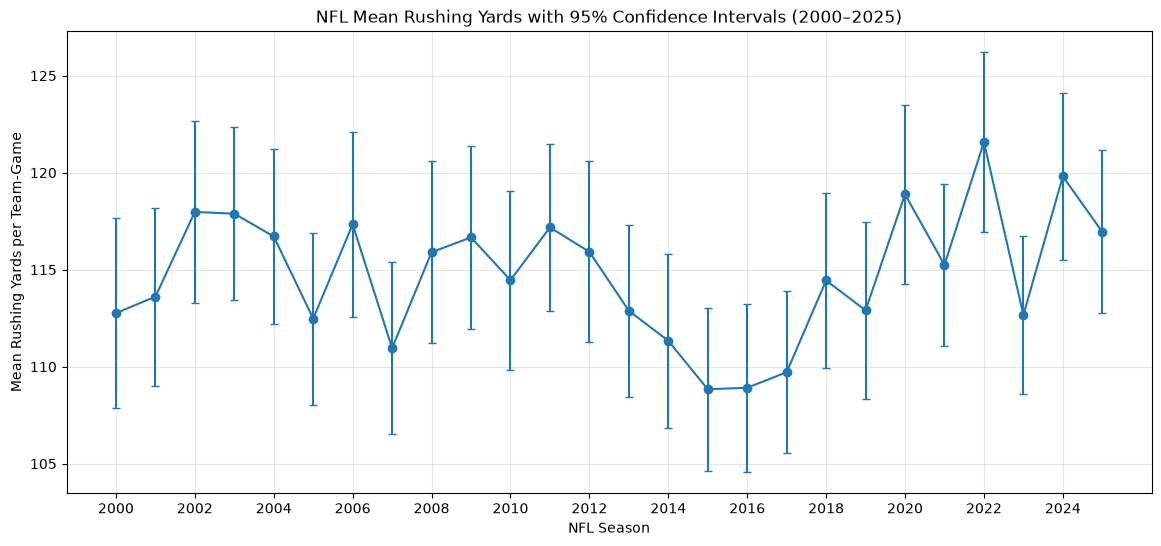

In [22]:

plt.figure(figsize=(14, 6))

plt.errorbar(
    rushing_ci["season"],
    rushing_ci["mean"],
    yerr=rushing_ci["margin_error"],
    fmt="o-",
    capsize=3
)

plt.title(
    "NFL Mean Rushing Yards with 95% Confidence Intervals (2000–2025)"
)
plt.xlabel("NFL Season")
plt.ylabel("Mean Rushing Yards per Team-Game")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()


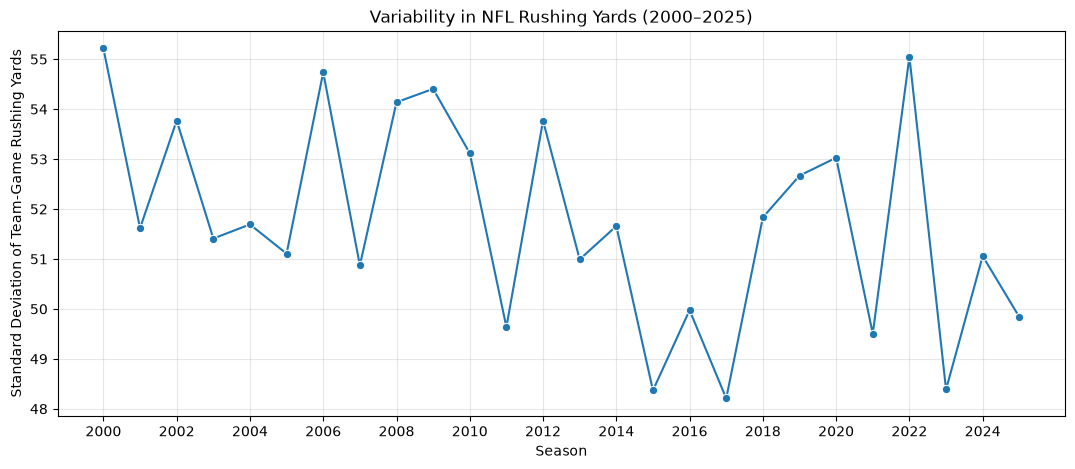

In [8]:
# analyzing game to game variability
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=season_summary,
    x="season",
    y="std",
    marker="o"
)

plt.title("Variability in NFL Rushing Yards (2000–2025)")
plt.xlabel("Season")
plt.ylabel("Standard Deviation of Team-Game Rushing Yards")
plt.xticks(range(2000, 2026, 2))
plt.grid(alpha=0.3)

plt.show()

### Historical Variability in Rushing Production (2000–2025)

The figure illustrates the annual standard deviation of rushing yards per team-game across 26 NFL regular seasons.

Seasonal standard deviations ranged from **48.21 to 55.21 rushing yards**, indicating that the dispersion of individual team-game performances varied throughout the study period.

The **highest standard deviation occurred in 2000 (55.21 yards)**, while the **lowest occurred in 2017 (48.21 yards)**. The seven-yard difference indicates that individual team-game rushing totals were more dispersed around their seasonal mean in 2000 than in 2017.

From 2000 through 2010, standard deviations fluctuated, frequently ranging between approximately 51 and 55 rushing yards. Between 2011 and 2017, several seasons exhibited comparatively lower dispersion, including the minimum observed in 2017.

From 2018 through 2025, variability continued to fluctuate, with a notable increase in 2022 followed by a sharp decline in 2023.

**An interesting observation is the 2022 season**, which recorded the highest average rushing production (121.58 yards per team-game) alongside one of the highest seasonal standard deviations (approximately 55 yards).

This indicates that 2022 combined relatively high average rushing production with substantial variation among individual team-game rushing totals.

However, the observed dispersion may reflect two different sources of variation:

- **Between-team variability:** Differences in average rushing production among NFL teams.
- **Within-team variability:** Differences in an individual team's rushing performance across games.

Because the current analysis pools all team-game observations within each season, it does not distinguish between these two components.

**Interpretation:** League-wide rushing variability fluctuated throughout the study period without a clear sustained increasing or decreasing trend. Further team-season analysis would help determine whether the observed dispersion was primarily associated with differences between teams or game-to-game fluctuations within teams.

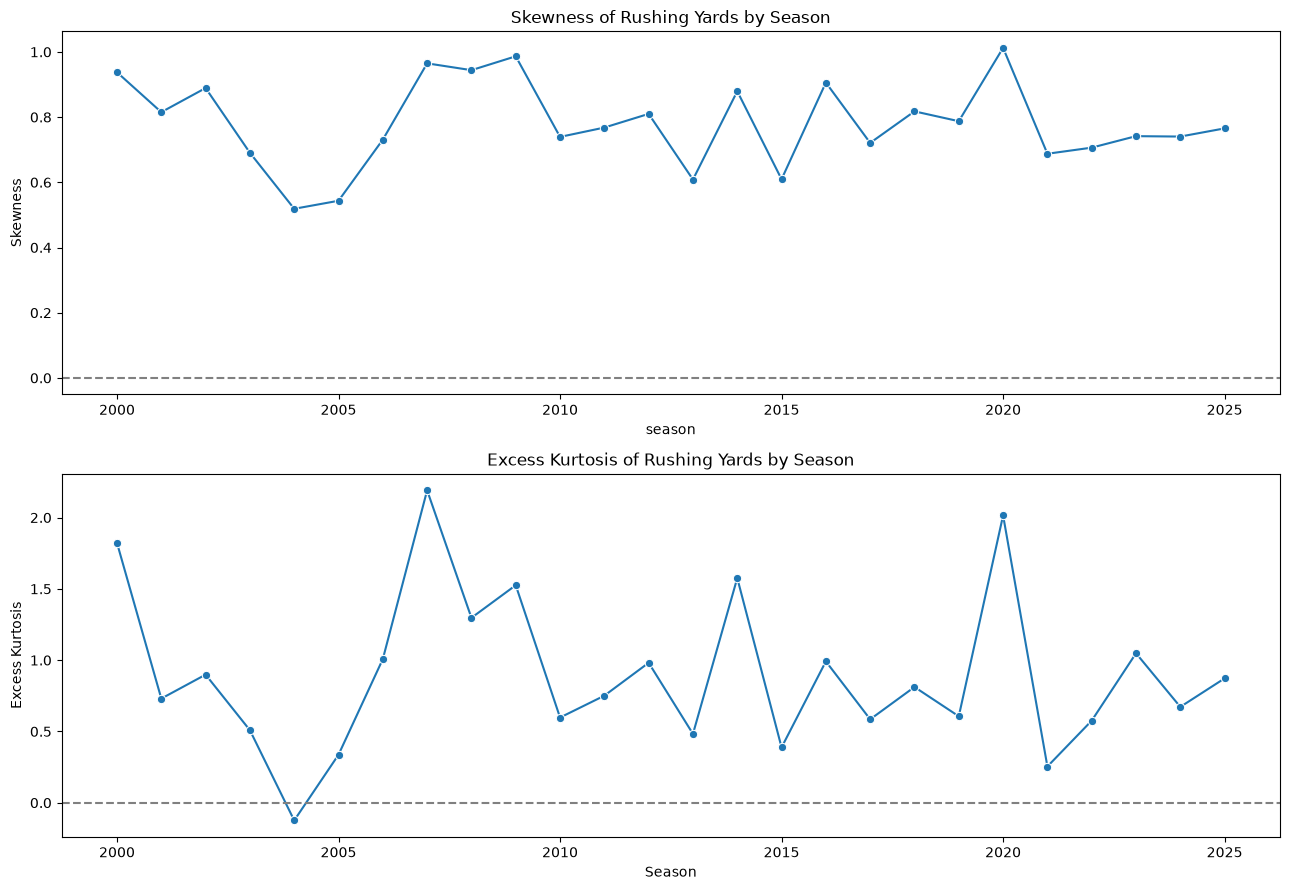

In [15]:
# skewness of rushing yards by season
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

sns.lineplot(
    data=season_summary,
    x="season",
    y="skewness",
    marker="o",
    ax=axes[0]
)

axes[0].axhline(0, linestyle="--", color="gray")
axes[0].set_title("Skewness of Rushing Yards by Season")
axes[0].set_ylabel("Skewness")

sns.lineplot(
    data=season_summary,
    x="season",
    y="kurtosis",
    marker="o",
    ax=axes[1]
)

axes[1].axhline(0, linestyle="--", color="gray")
axes[1].set_title("Excess Kurtosis of Rushing Yards by Season")
axes[1].set_ylabel("Excess Kurtosis")
axes[1].set_xlabel("Season")

plt.tight_layout()
plt.show()


### Historical Skewness in NFL Rushing Production (2000–2025)

The figure illustrates seasonal skewness in rushing yards per team-game across 26 NFL regular seasons.

All seasons exhibited **positive skewness**, with values ranging approximately from 0.52 to 1.01. This indicates that rushing-yard distributions were consistently right-skewed throughout the study period.

Positive skewness suggests that unusually high rushing-yard performances contributed to longer upper tails, while most team-game observations were concentrated at comparatively lower rushing-yard totals.

The greatest positive skewness occurred around **2020**, while the lowest occurred around **2004**, suggesting that the degree of distributional asymmetry varied across seasons.

Despite these fluctuations, there is no obvious sustained upward or downward trend in skewness across the full study period.

The pooled rushing-yard distribution exhibited a skewness coefficient of **0.789**, consistent with the positive asymmetry observed in the individual seasons.

**Interpretation:** Historical rushing performances were consistently characterized by right-skewed distributions, suggesting that exceptionally high rushing totals were less common but contributed to the upper tails of the distributions. However, skewness alone does not identify which teams generated these performances or how frequently particular teams achieved them.

### Historical Excess Kurtosis in NFL Rushing Production (2000–2025)

The figure illustrates annual excess kurtosis in rushing yards per team-game across 26 NFL regular seasons.

Excess kurtosis was positive in nearly every season, indicating that the fourth standardized moment generally exceeded the normal-distribution reference of zero.

The largest observed excess kurtosis occurred around **2007 (approximately 2.2)**, followed by another notable peak in **2020 (approximately 2.0)**.

Conversely, **2004 exhibited slightly negative excess kurtosis**, suggesting a fourth standardized moment marginally below the normal-distribution reference.

Across the entire study period, the pooled rushing-yard distribution exhibited **excess kurtosis of 0.935**.

**Interpretation:** The generally positive excess kurtosis is consistent with heavier tails than a normal distribution, although the magnitude varied substantially between seasons.

Periods with particularly elevated excess kurtosis warrant further examination of extreme rushing-yard performances. However, kurtosis alone does not establish the frequency or causes of these observations.

The fluctuations do not reveal a clear sustained historical trend in excess kurtosis.


In [16]:
season_stats = (
    subset.groupby("season")["rushing_yards"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        variance="var",
        minimum="min",
        maximum="max",
        skewness="skew",
        kurtosis=pd.Series.kurt
    )
)

season_stats["Q1"] = (
    subset.groupby("season")["rushing_yards"].quantile(0.25)
)

season_stats["Q3"] = (
    subset.groupby("season")["rushing_yards"].quantile(0.75)
)

season_stats["IQR"] = season_stats["Q3"] - season_stats["Q1"]

display(season_stats.round(2))

,count,mean,median,std,variance,minimum,maximum,skewness,kurtosis,Q1,Q3,IQR
season,,,,,,,,,,,,
2000,492,112.76,104.0,55.21,3048.69,4,407,0.94,1.82,73.00,143.0,70.00
2005,512,112.48,105.0,51.11,2611.82,6,320,0.54,0.34,75.75,146.0,70.25
2010,512,114.46,109.0,53.12,2821.50,13,328,0.74,0.60,76.00,144.0,68.00
2015,512,108.84,103.0,48.37,2339.53,7,283,0.61,0.39,74.00,137.0,63.00
2020,512,118.88,111.0,53.03,2811.83,8,404,1.01,2.02,85.00,144.0,59.00
2025,544,116.94,114.0,49.84,2483.82,15,323,0.77,0.87,79.00,146.0,67.00


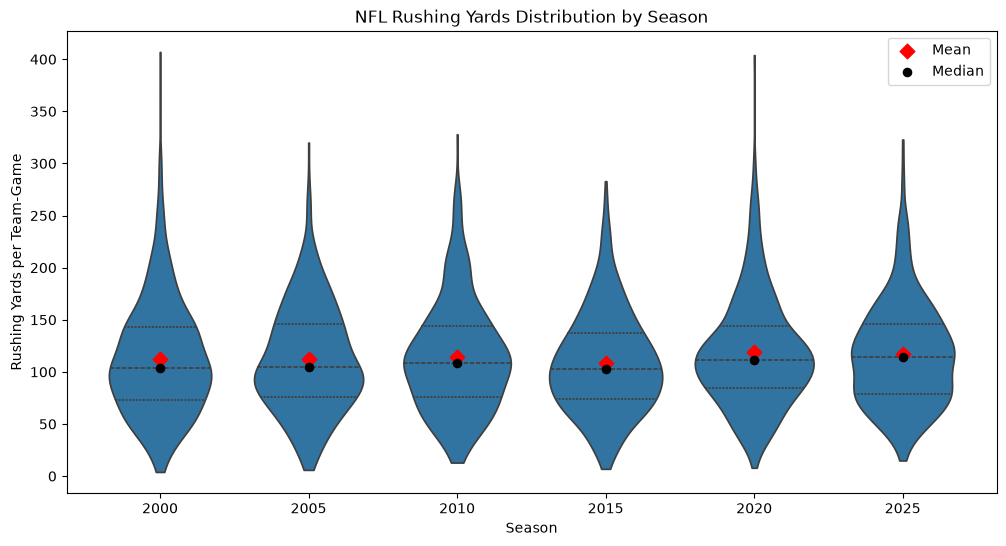

In [17]:
# comparing distrubuin across eras
selected_years = [2000, 2005, 2010, 2015, 2020, 2025]

subset = rushing.loc[
    rushing["season"].isin(selected_years)
].copy()

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=subset,
    x="season",
    y="rushing_yards",
    inner="quartile",
    cut=0
)

# Extract mean and median for each year
means = season_stats["mean"].values
medians = season_stats["median"].values

# Overlay mean and median markers
plt.scatter(
    range(len(means)),
    means,
    marker="D",
    color="red",
    s=55,
    label="Mean",
    zorder=5
)

plt.scatter(
    range(len(medians)),
    medians,
    marker="o",
    color="black",
    s=35,
    label="Median",
    zorder=5
)

plt.title("NFL Rushing Yards Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Rushing Yards per Team-Game")
plt.legend()
plt.show()



### Distributional Comparison of Selected NFL Seasons

The violin plots compare rushing yards per team-game across six selected NFL regular seasons: **2000, 2005, 2010, 2015, 2020, and 2025**.

Each violin represents the estimated distribution of rushing yards within a season, with wider regions indicating greater concentrations of observations at particular rushing-yard values.

The plotted mean and median markers allow for comparisons of central tendency alongside distributional shape.

Across the selected seasons, the means generally exceed their corresponding medians, consistent with the positive skewness identified in the seasonal analysis.

The distributions also exhibit relatively long upper tails, suggesting the presence of occasional unusually high rushing-yard performances.

The 2020 distribution extends toward particularly high rushing-yard totals, while the 2015 distribution appears centered at relatively lower values.

**Interpretation:** These visualizations reinforce the finding that rushing-yard distributions are positively skewed. Although the selected seasons differ in central tendency, spread, and tail behavior, their overall shapes exhibit several similarities.

Because violin plots display smoothed density estimates, their precise boundaries should not be interpreted as observed minimum or maximum rushing-yard totals.

Further team-level analysis will help identify which teams contributed to the observed differences in production and distributional shape.

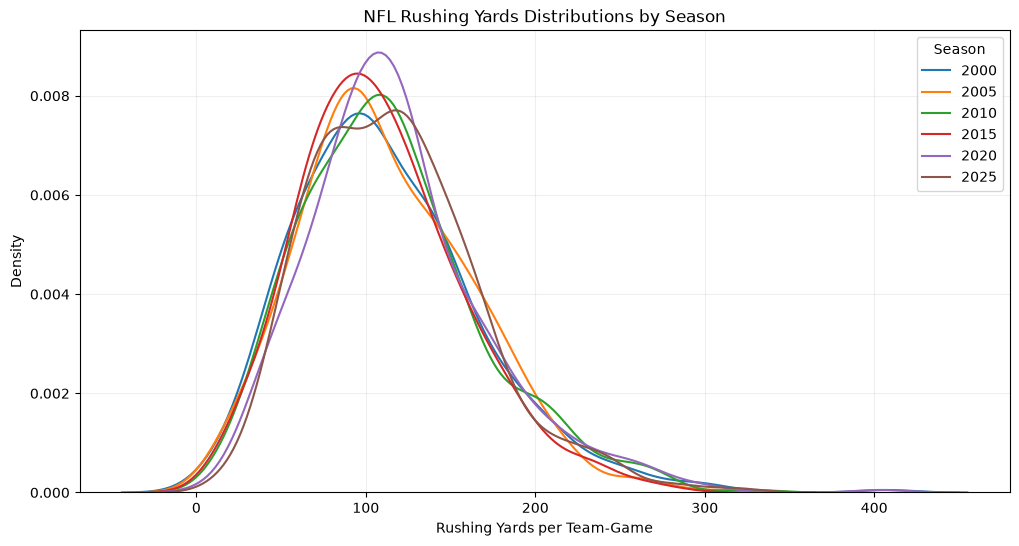

In [23]:

selected_years = [2000, 2005, 2010, 2015, 2020, 2025]

plt.figure(figsize=(12, 6))

for season in selected_years:
    season_data = rushing.loc[
        rushing["season"] == season,
        "rushing_yards"
    ].dropna()

    sns.kdeplot(
        season_data,
        label=str(season),
        fill=False
    )

plt.title("NFL Rushing Yards Distributions by Season")
plt.xlabel("Rushing Yards per Team-Game")
plt.ylabel("Density")
plt.legend(title="Season")
plt.grid(alpha=0.2)

plt.show()


In [18]:
"subset" in globals()

True

In [19]:
# saving in parquet to use locally
from pathlib import Path

DATA_DIR = Path.cwd()

if DATA_DIR.name == "notebooks":
    DATA_DIR = DATA_DIR.parent
elif DATA_DIR.name == "exploratory_analysis":
    DATA_DIR = DATA_DIR.parent.parent

(DATA_DIR / "data" / "processed").mkdir(
    parents=True, exist_ok=True
)

team_stats.to_parquet(
    DATA_DIR / "data" / "processed" / "team_stats_2000_2025.parquet",
    index=False
)

In [20]:

# Summary of historical rushing performance

summary = season_summary.copy()

highest_mean = summary.loc[summary["mean"].idxmax()]
lowest_mean = summary.loc[summary["mean"].idxmin()]

highest_std = summary.loc[summary["std"].idxmax()]
lowest_std = summary.loc[summary["std"].idxmin()]

mean_2000 = summary.loc[
    summary["season"] == 2000, "mean"
].iloc[0]

mean_2025 = summary.loc[
    summary["season"] == 2025, "mean"
].iloc[0]

print("NFL RUSHING PERFORMANCE: 2000–2025")
print("-" * 45)

print(f"Overall Mean: {rushing['rushing_yards'].mean():.2f}")
print(f"Overall Median: {rushing['rushing_yards'].median():.2f}")

print(f"Highest Mean: {int(highest_mean['season'])} ({highest_mean['mean']:.2f})")
print(f"Lowest Mean: {int(lowest_mean['season'])} ({lowest_mean['mean']:.2f})")

print(f"Highest SD: {int(highest_std['season'])} ({highest_std['std']:.2f})")
print(f"Lowest SD: {int(lowest_std['season'])} ({lowest_std['std']:.2f})")

print(f"2000 Mean: {mean_2000:.2f}")
print(f"2025 Mean: {mean_2025:.2f}")
print(f"Absolute Change: {mean_2025 - mean_2000:+.2f}")
print(f"Percentage Change: {(mean_2025 / mean_2000 - 1) * 100:+.2f}%")

print(f"Overall Skewness: {rushing['rushing_yards'].skew():.3f}")
print(f"Overall Excess Kurtosis: {rushing['rushing_yards'].kurt():.3f}")


NFL RUSHING PERFORMANCE: 2000–2025
---------------------------------------------
Overall Mean: 114.80
Overall Median: 108.00
Highest Mean: 2022 (121.58)
Lowest Mean: 2015 (108.84)
Highest SD: 2000 (55.21)
Lowest SD: 2017 (48.21)
2000 Mean: 112.76
2025 Mean: 116.94
Absolute Change: +4.19
Percentage Change: +3.71%
Overall Skewness: 0.789
Overall Excess Kurtosis: 0.935


## Conclusion: Historical NFL Rushing Performance (2000–2025)

This analysis examined rushing production across 26 NFL regular seasons, using individual team-game observations to investigate historical trends, variability, and distributional characteristics.

### Summary of Findings

Across the study period, the pooled average rushing production was **114.80 yards per team-game**, with a median of **108.00 yards**.

Seasonal averages fluctuated throughout the period, with the highest average recorded in **2022 (121.58 yards)** and the lowest in **2015 (108.84 yards)**. Although average rushing production increased by approximately **3.71% between 2000 and 2025**, the historical trajectory did not exhibit a consistent upward or downward pattern.

Variability also differed across seasons. Seasonal standard deviations ranged from **48.21 yards in 2017** to **55.21 yards in 2000**, indicating changes in the dispersion of individual team-game rushing totals.

The pooled distribution exhibited **positive skewness (0.789)** and **positive excess kurtosis (0.935)**, consistent with a longer upper tail and a fourth standardized moment above the normal-distribution reference.

Examination of individual seasons and selected violin plots revealed broadly similar right-skewed distributional patterns, despite differences in central tendency, dispersion, and tail behavior.

### Statistical Limitations

These findings are descriptive and do not establish causality or statistical significance.

Because observations represent individual team-game performances, the calculated seasonal variability combines differences between teams with game-to-game fluctuations within teams.

Furthermore, changes in offensive strategies, opponent strength, and league rules may have influenced rushing production throughout the study period.

### Future Research

Future investigations will extend this analysis to individual team-season averages and game-level matchups.

These analyses will help distinguish between-team and within-team variation, identify consistently productive rushing offenses, and investigate how rushing performance depends on opposing defenses.

The findings presented here establish a historical statistical baseline for the broader *Beyond the Chains* research project.